# Softmax and Temperature Example

This notebook generates 10 random numbers, computes the unnormalized softmax values `y = exp(x / t)`, normalizes them to get `z`, and compares the results across multiple temperatures.

The table shows `temperature`, `x`, `y`, and `z` for each of 10 generated values.

In [12]:
import numpy as np
import pandas as pd

# Fix random seed for reproducible results
np.random.seed(42)

# Generate 10 random values from a standard normal distribution
x_values = np.random.randn(10)

# Temperatures to compare
temperatures = [0, 1,2,3,4,5,6,7,8,9,10,100, 1000]

# Display the base x values so we can compare across temperatures
pd.DataFrame({'x': x_values})

,x
0,0.496714
1,-0.138264
2,0.647689
3,1.523030
4,-0.234153
5,-0.234137
6,1.579213
7,0.767435
8,-0.469474
9,0.542560


In [13]:
import plotly.graph_objects as go
import numpy as np

# Color bars by sign: positive = teal, negative = coral
bar_colors = ['#00b4d8' if v >= 0 else '#e63946' for v in x_values]

hover_texts = [
    f'<b>Token {i}</b><br>'
    f'<b>Logit:</b> {x_values[i]:.6f}<br>'
    f'<b>Rank:</b> {int(np.argsort(x_values)[::-1].tolist().index(i)) + 1} of {len(x_values)}<br>'
    f'<b>Sign:</b> {"positive" if x_values[i] >= 0 else "negative"}'
    for i in range(len(x_values))
]

fig = go.Figure(go.Bar(
    x=list(range(len(x_values))),
    y=x_values,
    marker=dict(
        color=bar_colors,
        line=dict(color='rgba(255,255,255,0.2)', width=1),
        opacity=0.9,
    ),
    hovertext=hover_texts,
    hoverinfo='text',
    text=[f'{v:.3f}' for v in x_values],
    textposition='outside',
    textfont=dict(color='white', size=11),
))

# Reference line at 0
fig.add_hline(y=0, line=dict(color='rgba(255,255,255,0.3)', width=1, dash='dot'))

fig.update_layout(
    title=dict(
        text='<b>Raw Logits (before softmax)</b>',
        font=dict(size=17, color='white'),
        x=0.5,
        xanchor='center',
    ),
    xaxis=dict(
        title='Token index',
        tickmode='linear',
        tick0=0,
        dtick=1,
        gridcolor='rgba(255,255,255,0.06)',
        zeroline=False,
    ),
    yaxis=dict(
        title='Logit value',
        gridcolor='rgba(255,255,255,0.06)',
        zeroline=False,
    ),
    paper_bgcolor='#0f0f1a',
    plot_bgcolor='#1a1a2e',
    font=dict(color='#e0e0e0', family='monospace'),
    hoverlabel=dict(
        bgcolor='#1e1e3f',
        bordercolor='#00b4d8',
        font=dict(color='white', size=12),
    ),
    height=420,
    margin=dict(t=80, b=60),
    annotations=[
        dict(
            text=f'min={x_values.min():.3f}   max={x_values.max():.3f}   mean={x_values.mean():.3f}   std={x_values.std():.3f}',
            xref='paper', yref='paper',
            x=0.5, y=-0.18,
            showarrow=False,
            font=dict(size=11, color='#aaaacc'),
            xanchor='center',
        )
    ]
)

fig.show()


In [14]:
def softmax_with_temperature(x, t):
    """Compute softmax for vector x at temperature t."""
    y = np.exp(x / t)
    z = y / np.sum(y)
    return y, z

rows = []

for t in temperatures:
    y_values, z_values = softmax_with_temperature(x_values, t)
    rows.append({
        'temperature': t,
        'x': x_values.tolist(),
        'y = exp(x/t)': y_values.tolist(),
        'z = y / sum(y)': z_values.tolist()
    })

softmax_df = pd.DataFrame(rows)
softmax_df[['temperature', 'x', 'y = exp(x/t)', 'z = y / sum(y)']]


/var/folders/ln/wnlskp1x37b55stm67grjq8w0000gn/T/ipykernel_8567/1641878885.py:3: RuntimeWarning: divide by zero encountered in divide
  y = np.exp(x / t)
/var/folders/ln/wnlskp1x37b55stm67grjq8w0000gn/T/ipykernel_8567/1641878885.py:4: RuntimeWarning: invalid value encountered in divide
  z = y / np.sum(y)


,temperature,x,y = exp(x/t),z = y / sum(y)
0,0,"[0.4967141530112327, -0.13826430117118466, 0.6...","[inf, 0.0, inf, inf, 0.0, 0.0, inf, inf, 0.0, ...","[nan, 0.0, nan, nan, 0.0, 0.0, nan, nan, 0.0, ..."
1,1,"[0.4967141530112327, -0.13826430117118466, 0.6...","[1.6433127155860012, 0.8708684897640193, 1.911...","[0.08239222398256223, 0.043663504205531514, 0...."
2,2,"[0.4967141530112327, -0.13826430117118466, 0.6...","[1.281917593133818, 0.9332033485602264, 1.3824...","[0.09645155007428488, 0.0702142711709793, 0.10..."
3,3,"[0.4967141530112327, -0.13826430117118466, 0.6...","[1.1800671980275215, 0.9549578263272578, 1.240...","[0.09895752928153247, 0.0800804117082189, 0.10..."
4,4,"[0.4967141530112327, -0.13826430117118466, 0.6...","[1.1322179971780248, 0.9660245072254774, 1.175...","[0.09972141363695997, 0.08508372920106944, 0.1..."
5,5,"[0.4967141530112327, -0.13826430117118466, 0.6...","[1.1044448721627087, 0.9727259800672337, 1.138...","[0.10001884172183717, 0.08809034139345483, 0.1..."
6,6,"[0.4967141530112327, -0.13826430117118466, 0.6...","[1.0863089790789366, 0.9772194361182435, 1.113...","[0.10014971334321596, 0.09009245830191157, 0.1..."
7,7,"[0.4967141530112327, -0.13826430117118466, 0.6...","[1.0735373867690814, 0.9804417505403241, 1.096...","[0.10021017395249388, 0.09152009010848466, 0.1..."
8,8,"[0.4967141530112327, -0.13826430117118466, 0.6...","[1.0640573279565462, 0.9828654573365967, 1.084...","[0.10023749108497074, 0.09258896577189508, 0.1..."
9,9,"[0.4967141530112327, -0.13826430117118466, 0.6...","[1.0567418640929174, 0.984754704162961, 1.0746...","[0.1002480759979167, 0.09341899642347684, 0.10..."


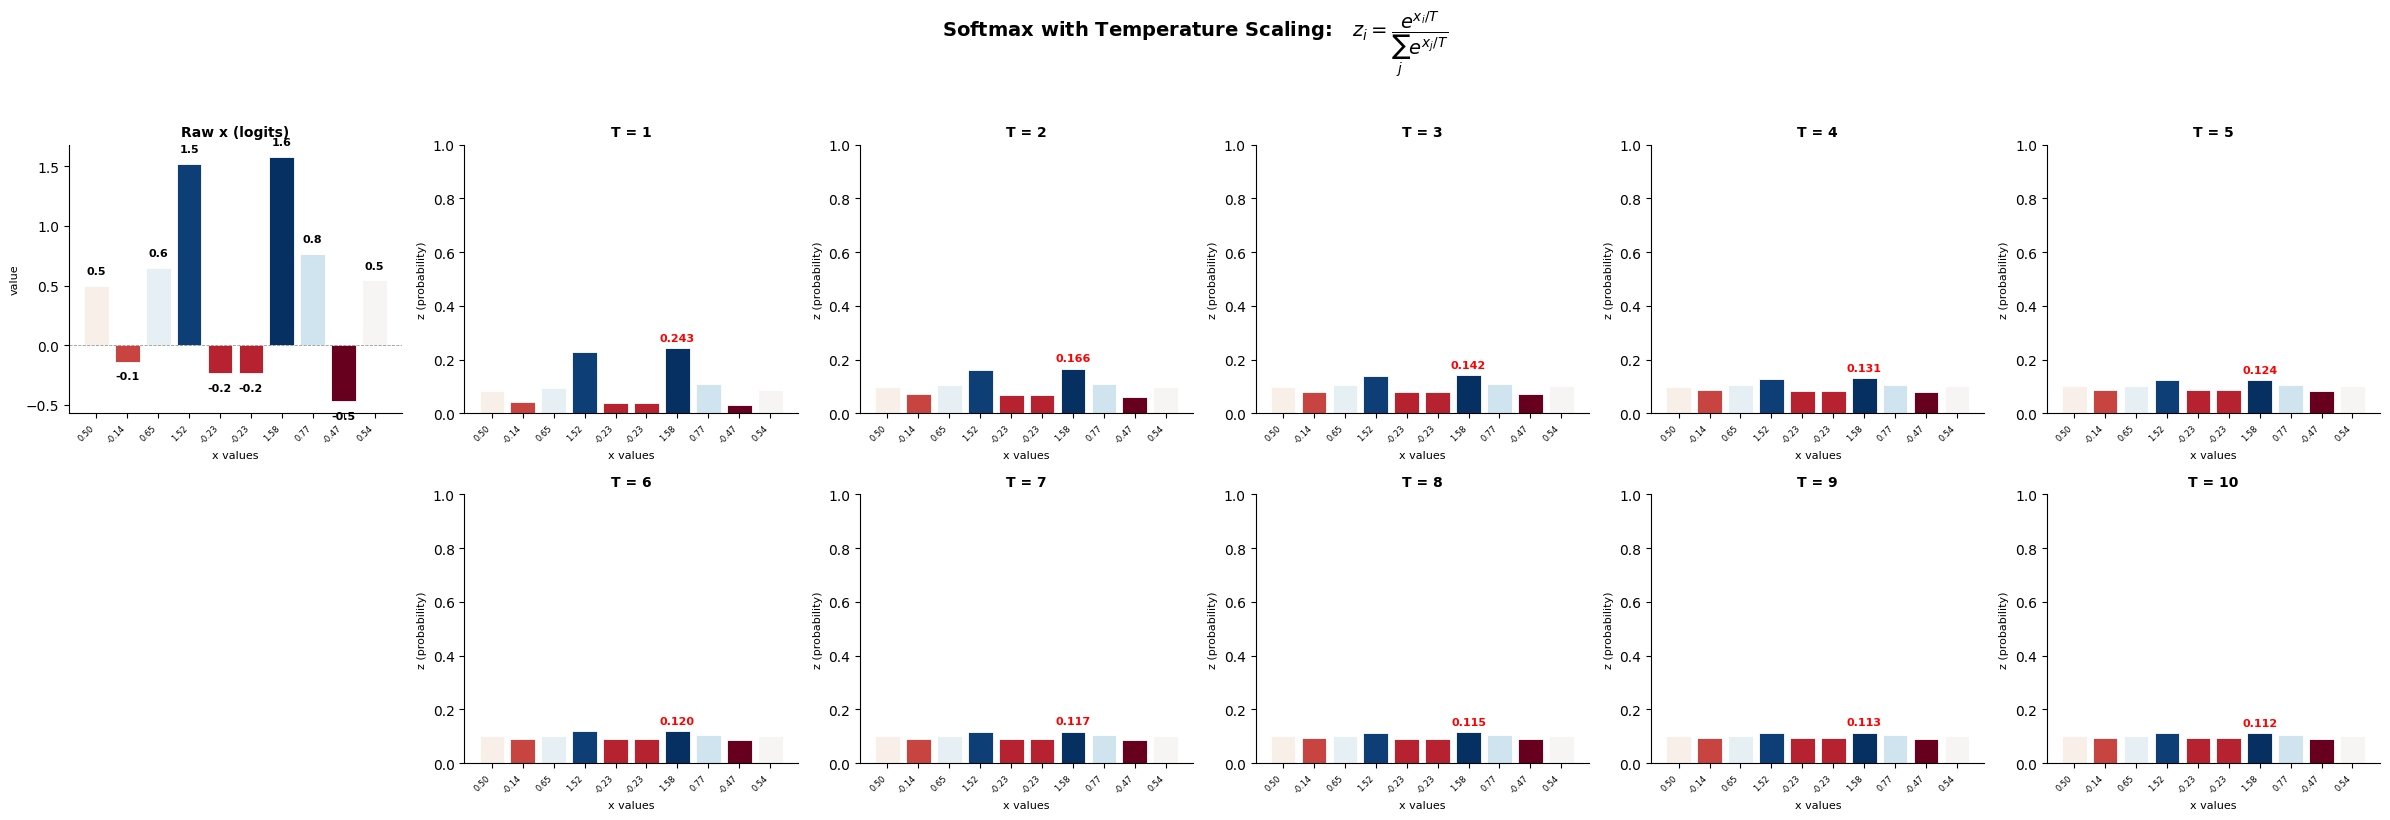

In [15]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import numpy as np

# --- Color mapping: low x → red, high x → blue (RdBu colormap) ---
norm = mcolors.Normalize(vmin=x_values.min(), vmax=x_values.max())
cmap = cm.RdBu

def bar_colors(vals):
    return [cmap(norm(v)) for v in vals]

x_labels = [f'{v:.2f}' for v in x_values]

# --- Layout: 2 rows × 6 cols, bottom-left cell hidden ---
fig, axes = plt.subplots(2, 6, figsize=(24, 8))
fig.suptitle(
    r'Softmax with Temperature Scaling:   $z_i = \dfrac{e^{x_i/T}}{\sum_j e^{x_j/T}}$',
    fontsize=14, fontweight='bold', y=1.02
)

# ── Raw logits (top-left) ──────────────────────────────────────────────────
ax0 = axes[0, 0]
colors0 = bar_colors(x_values)
bars0 = ax0.bar(range(len(x_values)), x_values, color=colors0,
                edgecolor='white', linewidth=0.6)

span = x_values.max() - x_values.min()
for bar, v in zip(bars0, x_values):
    offset = span * 0.04 if v >= 0 else -span * 0.04
    va = 'bottom' if v >= 0 else 'top'
    ax0.text(bar.get_x() + bar.get_width() / 2, v + offset,
             f'{round(v, 1)}', ha='center', va=va, fontsize=8, fontweight='bold')

ax0.set_title('Raw x (logits)', fontsize=10, fontweight='bold')
ax0.set_xlabel('x values', fontsize=8)
ax0.set_ylabel('value', fontsize=8)
ax0.set_xticks(range(len(x_values)))
ax0.set_xticklabels(x_labels, fontsize=6, rotation=45, ha='right')
ax0.axhline(0, color='black', linewidth=0.6, linestyle='--', alpha=0.4)
ax0.spines[['top', 'right']].set_visible(False)

# Hide bottom-left cell
axes[1, 0].set_visible(False)

# ── Softmax subplots ───────────────────────────────────────────────────────
temps = list(range(1, 11))
positions = [
    (0, 1), (0, 2), (0, 3), (0, 4), (0, 5),
    (1, 1), (1, 2), (1, 3), (1, 4), (1, 5),
]

for idx, t in enumerate(temps):
    r, c = positions[idx]
    ax = axes[r, c]

    _, z_vals = softmax_with_temperature(x_values, t)
    bc = bar_colors(x_values)

    ax.bar(range(len(z_vals)), z_vals, color=bc, edgecolor='white', linewidth=0.6)

    # Label the dominant token in red
    max_idx = int(np.argmax(z_vals))
    ax.text(max_idx, z_vals[max_idx] + 0.02, f'{z_vals[max_idx]:.3f}',
            ha='center', va='bottom', fontsize=8, color='red', fontweight='bold')

    ax.set_title(f'T = {t}', fontsize=10, fontweight='bold')
    ax.set_xlabel('x values', fontsize=8)
    ax.set_ylabel('z (probability)', fontsize=8)
    ax.set_ylim(0, 1.0)
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_xticks(range(len(x_values)))
    ax.set_xticklabels(x_labels, fontsize=6, rotation=45, ha='right')
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()


In [16]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np

unique_temps = softmax_df['temperature'].unique()[:10]

# Blue → teal → green → amber → red gradient across temperatures
colors = [
    '#4361ee', '#3a86ff', '#0096c7', '#00b4d8',
    '#48cae4', '#52b788', '#95d5b2', '#d4a017',
    '#f77f00', '#d62828'
]

fig = make_subplots(
    rows=2, cols=5,
    subplot_titles=[f'T = {t}' for t in unique_temps],
    horizontal_spacing=0.07,
    vertical_spacing=0.2
)

bins = np.linspace(0, 1, 11)

for i, t in enumerate(unique_temps):
    row = i // 5 + 1
    col = i % 5 + 1

    z_vals = np.array(softmax_df[softmax_df['temperature'] == t]['z = y / sum(y)'].values[0])
    counts, edges = np.histogram(z_vals, bins=bins)
    bin_centers = (edges[:-1] + edges[1:]) / 2

    mean_z   = z_vals.mean()
    std_z    = z_vals.std()
    entropy  = -np.sum(z_vals * np.log(z_vals + 1e-10))
    max_z    = z_vals.max()
    min_z    = z_vals.min()
    dominant = int(np.argmax(z_vals))

    hover_texts = [
        f'<b>Bin:</b> [{edges[j]:.2f}, {edges[j+1]:.2f})<br>'
        f'<b>Count:</b> {counts[j]}<br>'
        f'──────────────<br>'
        f'<b>Temperature:</b> {t}<br>'
        f'<b>Mean z:</b> {mean_z:.4f}<br>'
        f'<b>Std z:</b> {std_z:.4f}<br>'
        f'<b>Max z:</b> {max_z:.4f} (token {dominant})<br>'
        f'<b>Min z:</b> {min_z:.4f}<br>'
        f'<b>Entropy:</b> {entropy:.4f} nats'
        for j in range(len(counts))
    ]

    fig.add_trace(
        go.Bar(
            x=bin_centers,
            y=counts,
            width=0.085,
            marker=dict(
                color=colors[i],
                line=dict(color='rgba(255,255,255,0.25)', width=1),
                opacity=0.88,
            ),
            hovertext=hover_texts,
            hoverinfo='text',
            name=f'T={t}',
            showlegend=False,
        ),
        row=row, col=col
    )

fig.update_layout(
    title=dict(
        text='<b>Softmax Probability Distributions at Different Temperatures</b>',
        font=dict(size=17, color='white'),
        x=0.5,
        xanchor='center',
    ),
    height=640,
    paper_bgcolor='#0f0f1a',
    plot_bgcolor='#1a1a2e',
    font=dict(color='#e0e0e0', family='monospace'),
    hoverlabel=dict(
        bgcolor='#1e1e3f',
        bordercolor='#4361ee',
        font=dict(color='white', size=12),
    ),
    margin=dict(t=110, b=60),
)

fig.update_xaxes(
    title_text='Probability (z)',
    range=[0, 1],
    tickfont=dict(size=8),
    gridcolor='rgba(255,255,255,0.06)',
    zeroline=False,
)
fig.update_yaxes(
    title_text='Count',
    tickfont=dict(size=8),
    gridcolor='rgba(255,255,255,0.06)',
    zeroline=False,
)

fig.show()
